# Week 4 – Seoul Bike Sharing | Replay-mode Digital Twin (Team B)

**Homework:** Observe → Synchronize (`K = 0.5`) → Predict next hour → Validate → Repeat.

The **Week 3 model is unchanged**: month–hour baseline × four weather effects. The new part is a stateful, chronological replay loop. The notebook produces **two plots**, comparable MAE values, and a short discussion.

**Important:** The next-hour weather is **not read from the future row**. We use the latest observed weather as a simple persistence forecast. The next hour's operating schedule is assumed to be known. This is a historical replay prototype, not a live Digital Twin.

**Scope:** Seoul data only. The homework also asks Team B to look for *new city/cities*; that is an outstanding data-source extension, not claimed as implemented here.

## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load and check observations

In [2]:
csv_path = Path('../SeoulBikeData.csv')
if not csv_path.exists():
    csv_path = Path('SeoulBikeData.csv')

if not csv_path.exists():
    raise FileNotFoundError('Place SeoulBikeData.csv in the repository root or notebook folder.')

df = pd.read_csv(csv_path, encoding='latin1')
df['Timestamp'] = (pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
                   + pd.to_timedelta(df['Hour'], unit='h'))

weather = ['Temperature(°C)', 'Humidity(%)', 'Rainfall(mm)', 'Wind speed (m/s)']
cols = ['Timestamp', 'Hour', 'Functioning Day', 'Rented Bike Count'] + weather

print('Original rows:', len(df))
print('Missing values:', df[cols].isna().sum().sum())
print('Duplicate timestamps:', df['Timestamp'].duplicated().sum())
print('Invalid rental counts:', (df['Rented Bike Count'] < 0).sum())
print('Invalid hours:', (~df['Hour'].between(0, 23)).sum())
print('Invalid humidity:', (~df['Humidity(%)'].between(0, 100)).sum())
print('Invalid rainfall:', (df['Rainfall(mm)'] < 0).sum())
print('Invalid wind speed:', (df['Wind speed (m/s)'] < 0).sum())
print('Invalid operating status:', (~df['Functioning Day'].isin(['Yes', 'No'])).sum())

valid = (df['Hour'].between(0, 23)
         & (df['Rented Bike Count'] >= 0)
         & df['Humidity(%)'].between(0, 100)
         & (df['Rainfall(mm)'] >= 0)
         & (df['Wind speed (m/s)'] >= 0)
         & df['Functioning Day'].isin(['Yes', 'No']))

df = (df.loc[valid, cols].dropna().drop_duplicates('Timestamp')
      .sort_values('Timestamp').reset_index(drop=True))
df['Month'] = df['Timestamp'].dt.month
df['Day'] = df['Timestamp'].dt.date

print('Clean rows:', len(df))
print('Chronologically sorted:', df['Timestamp'].is_monotonic_increasing)
print('Start:', df['Timestamp'].min(), '| End:', df['Timestamp'].max())

Original rows: 8760
Missing values: 0
Duplicate timestamps: 0
Invalid rental counts: 0
Invalid hours: 0
Invalid humidity: 0
Invalid rainfall: 0
Invalid wind speed: 0
Invalid operating status: 0
Clean rows: 8760
Chronologically sorted: True
Start: 2017-12-01 00:00:00 | End: 2018-11-30 23:00:00


## 3. Rebuild the original Week 3 simulation (same equations)

Within each calendar month, the first approximately 80% of **complete days** are training data, and the remaining days are held out for the replay evaluation.

In [3]:
train_parts, test_parts = [], []
for month, group in df.groupby('Month'):
    days = sorted(group['Day'].unique())
    cutoff = int(len(days) * 0.8)
    train_parts.append(group[group['Day'].isin(days[:cutoff])])
    test_parts.append(group[group['Day'].isin(days[cutoff:])])

train = pd.concat(train_parts).sort_values('Timestamp').copy()
test = pd.concat(test_parts).sort_values('Timestamp').copy()
print('Training rows:', len(train), '| Test rows:', len(test))

Training rows: 6864 | Test rows: 1896


In [4]:
active = train[train['Functioning Day'] == 'Yes'].copy()
monthly_weather = train.groupby('Month')[weather].mean()
rental_average = active.groupby(['Month', 'Hour'])['Rented Bike Count'].mean()

active['Baseline'] = [rental_average.loc[m, h] for m, h in zip(active['Month'], active['Hour'])]
active = active[active['Baseline'] > 0].copy()
active['Relative Rentals'] = active['Rented Bike Count'] / active['Baseline']

weather_effects = {}
for column in weather:
    above = active[column] >= active['Month'].map(monthly_weather[column])
    averages = active.groupby(['Month', above])['Relative Rentals'].mean()
    for month in monthly_weather.index:
        for is_above in [False, True]:
            weather_effects[(month, column, is_above)] = averages.get((month, is_above), 1.0)

# Week 3 equation, evaluated for potential demand while service is operating.
def demand_baseline(row):
    month, hour = row['Month'], row['Hour']
    estimate = rental_average.loc[month, hour]
    for column in weather:
        is_above = row[column] >= monthly_weather.loc[month, column]
        estimate *= weather_effects[(month, column, is_above)]
    return float(estimate)

# Original Week 3 observation model: zero completed rentals when service is closed.
def simulate(row):
    if row['Functioning Day'] == 'No':
        return 0.0
    return demand_baseline(row)

test['S'] = test.apply(simulate, axis=1)
print('Week 3 simulation ready.')

Week 3 simulation ready.


## 4. Synchronization and chronological replay

- **State** `D_sim(t)`: demand forecast carried from the previous hour (or the Week 3 baseline at restart).
- **Update** `D_updated(t) = D_sim(t) + 0.5 × (D_obs(t) − D_sim(t))` on operating hours.
- **Change** `ΔD(t) = S_forecast(t+1) − S(t)`, calculated from the **unchanged Week 3 equation** using the latest known weather for both hours.
- **Prediction** `D_pred(t+1) = max(0, D_updated(t) + ΔD(t))`.

When the service is closed, the observed zero does **not** update latent demand. Reported completed rentals are zero during closure. The model restarts at test-set gaps, because they are not consecutive hours. Internal state stays floating-point; round only for displayed counts.

For the first graph we store **the state before and after correction at time t**. For the second graph we store **the prediction for t+1 before validating it against the t+1 observation**.

In [10]:
K = 0.5  # Required by the homework

def synchronize(simulated, observed):
    return simulated + K * (observed - simulated)


def run_twin(data):
    rows = data.sort_values('Timestamp').to_dict('records')
    states = []
    forecasts = []
    predicted_state = None

    for i, current in enumerate(rows):
        # A new, nonconsecutive test block starts from the original model.
        if i == 0 or current['Timestamp'] - rows[i - 1]['Timestamp'] != pd.Timedelta(hours=1):
            predicted_state = demand_baseline(current)

        simulated_state = predicted_state
        observed = current['Rented Bike Count']
        operating = current['Functioning Day'] == 'Yes'

        # Observe -> synchronize (only if rentals reveal demand).
        updated_state = synchronize(simulated_state, observed) if operating else simulated_state
        updated_state = max(0.0, updated_state)

        states.append({
            'Timestamp': current['Timestamp'],
            'Observed': observed if operating else float('nan'),
            'Simulated': simulated_state,
            'Synchronized': updated_state,
            'Operating': operating,
        })

        if i == len(rows) - 1:
            break
        nxt = rows[i + 1]
        if nxt['Timestamp'] - current['Timestamp'] != pd.Timedelta(hours=1):
            predicted_state = None
            continue

        # Predict next hour WITHOUT reading next-hour rental count or weather.
        # The next hour and operating schedule are treated as known.
        next_inputs = current.copy()
        next_inputs['Timestamp'] = nxt['Timestamp']
        next_inputs['Month'] = nxt['Timestamp'].month
        next_inputs['Hour'] = nxt['Timestamp'].hour
        next_inputs['Functioning Day'] = nxt['Functioning Day']

        current_baseline = demand_baseline(current)
        next_baseline = demand_baseline(next_inputs)  # current weather persisted
        delta = next_baseline - current_baseline
        predicted_state = max(0.0, updated_state + delta)

        # Save forecast first. Read next observation only in the next iteration.
        forecasts.append({
            'Timestamp': nxt['Timestamp'],
            'Week 3 simulation': nxt['S'],  # benchmark prepared separately
            'Twin prediction': predicted_state if nxt['Functioning Day'] == 'Yes' else 0.0,
            'Operating': nxt['Functioning Day'] == 'Yes',
        })

    states = pd.DataFrame(states)
    forecasts = pd.DataFrame(forecasts)

    # Validate the saved predictions after the entire replay has finished.
    observations = data[['Timestamp', 'Rented Bike Count']].rename(
        columns={'Rented Bike Count': 'Observed'}
    )
    forecasts = forecasts.merge(observations, on='Timestamp', how='left', validate='one_to_one')
    return states, forecasts

states, forecasts = run_twin(test)
print('Saved synchronized states:', len(states))
print('Saved next-hour forecasts:', len(forecasts))
print(forecasts.head(8).round(2).to_string(index=False))

Saved synchronized states: 1896
Saved next-hour forecasts: 1884
          Timestamp  Week 3 simulation  Twin prediction  Operating  Observed
2017-12-25 01:00:00             195.43           174.86       True       132
2017-12-25 02:00:00             167.19           103.99       True       115
2017-12-25 03:00:00             102.93            52.08       True       100
2017-12-25 04:00:00              62.43            35.53       True        72
2017-12-25 05:00:00              62.64            53.97       True        32
2017-12-25 06:00:00              98.52            78.87       True        59
2017-12-25 07:00:00             229.09           199.51       True        61
2017-12-25 08:00:00             467.94           369.10       True        94


C:\Users\hazid\AppData\Local\Temp\ipykernel_13944\2064255752.py:75: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(forecasts.head(8).round(2).to_string(index=False))


## 5. Plot 1 – Observed, simulated and synchronized states

**This is an analysis of the current-hour correction, not a next-hour forecast.** Non-operating hours are excluded from this demand-state comparison.

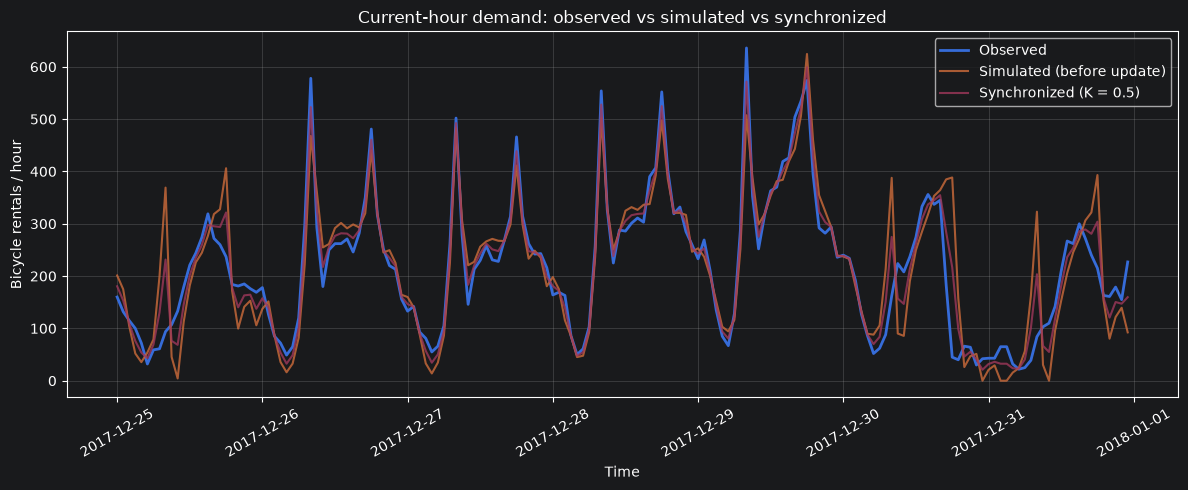

In [11]:
first_month = states['Timestamp'].dt.month.iloc[0]
plot_states = states[(states['Timestamp'].dt.month == first_month) & states['Operating']].head(168)

plt.figure(figsize=(12, 5))
plt.plot(plot_states['Timestamp'], plot_states['Observed'], label='Observed', linewidth=2)
plt.plot(plot_states['Timestamp'], plot_states['Simulated'], label='Simulated (before update)', alpha=0.8)
plt.plot(plot_states['Timestamp'], plot_states['Synchronized'], label='Synchronized (K = 0.5)', alpha=0.8)
plt.title('Current-hour demand: observed vs simulated vs synchronized')
plt.xlabel('Time')
plt.ylabel('Bicycle rentals / hour')
plt.xticks(rotation=30)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Plot 2 – One-step-ahead forecasts vs observations

These predictions were saved **before** the corresponding next-hour observations were used. Both the original Week 3 baseline and the synchronized twin are evaluated at the same timestamps.

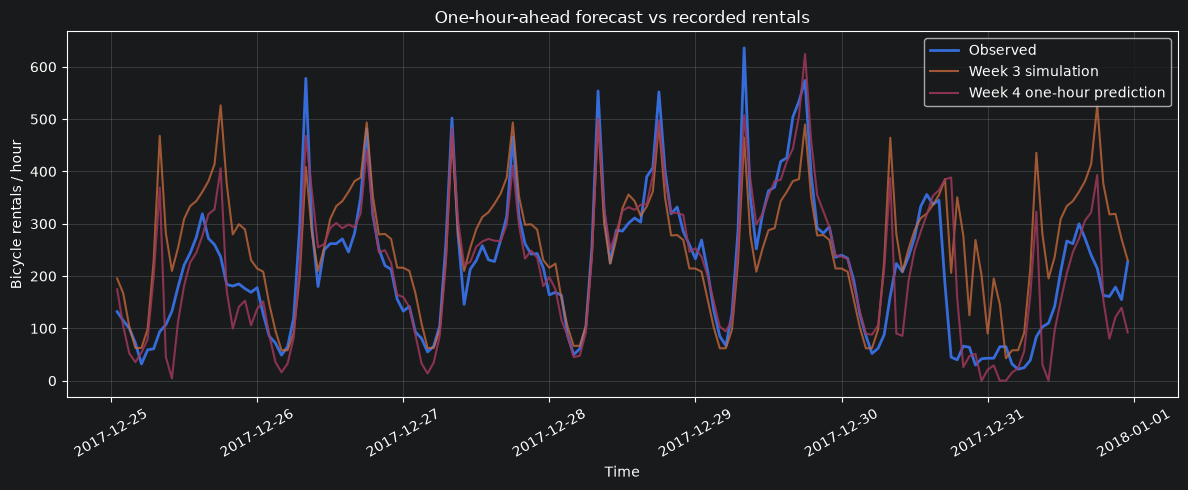

In [12]:
plot_forecasts = forecasts[(forecasts['Timestamp'].dt.month == first_month) & forecasts['Operating']].head(168)

plt.figure(figsize=(12, 5))
plt.plot(plot_forecasts['Timestamp'], plot_forecasts['Observed'], label='Observed', linewidth=2)
plt.plot(plot_forecasts['Timestamp'], plot_forecasts['Week 3 simulation'], label='Week 3 simulation', alpha=0.75)
plt.plot(plot_forecasts['Timestamp'], plot_forecasts['Twin prediction'], label='Week 4 one-hour prediction', alpha=0.85)
plt.title('One-hour-ahead forecast vs recorded rentals')
plt.xlabel('Time')
plt.ylabel('Bicycle rentals / hour')
plt.xticks(rotation=30)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Mean Absolute Error (MAE)

MAE is calculated over **the same operating-hour timestamps** for both models. Smaller is better. No improvement is assumed in advance.

In [13]:
evaluation = forecasts[forecasts['Operating']].copy()
mae_week3 = (evaluation['Observed'] - evaluation['Week 3 simulation']).abs().mean()
mae_week4 = (evaluation['Observed'] - evaluation['Twin prediction']).abs().mean()

print(f'Week 3 MAE: {mae_week3:.2f} bicycles/hour')
print(f'Week 4 MAE: {mae_week4:.2f} bicycles/hour')
print('Evaluated operating hours:', len(evaluation))
if mae_week3 > 0:
    print(f'MAE change: {(mae_week4 / mae_week3 - 1) * 100:+.1f}% (negative means improvement)')

Week 3 MAE: 222.17 bicycles/hour
Week 4 MAE: 135.36 bicycles/hour
Evaluated operating hours: 1836
MAE change: -39.1% (negative means improvement)


## 8. Discussion (short explanation)

**How is the Digital Twin different from the original simulation?**

The Week 3 model independently estimated rentals from month–hour historical averages and weather effects. The Week 4 replay-mode Digital Twin keeps the same simulation equation, but processes observations in chronological order and uses each available current-hour rental count to correct its demand state with **K = 0.5**. It then predicts the following hour and compares the saved prediction against the later observation. Two plots show (1) current-hour state synchronization and (2) next-hour prediction accuracy. MAE compares the original baseline and synchronized model at identical evaluation timestamps.

**Limitations:** Rental counts are a proxy for latent demand only when the service operates. The next-hour weather is approximated by the current weather (persistence forecast). The next-hour operating status is assumed known. Train/test days are split within each month, so this does not demonstrate generalization to entirely unseen months. This is a historical replay prototype, not a live twin. The additional *new city/cities* request requires another suitable dataset and is not implemented here.

**Five-minute demo:** (1) show data checks; (2) show the unchanged Week 3 equation; (3) explain the fixed K and replay loop; (4) explain both plots; (5) read the two MAE values and discuss limitations.